# NexaTel Customer Churn Analytics

## Phase 2 — Exploratory Data Analysis

**Project:** NexaTel Customer Churn Analytics  
**Phase:** 2 — Exploratory Data Analysis (EDA)  
**Analyst:** Kashif Siddique  
**Tools:** Python, Pandas, NumPy, Matplotlib, Jupyter Notebook

### Objective

To explore the cleaned NexaTel telecom datasets through data visualization and
customer-level analysis in order to understand **who is churning, where churn is
concentrated, and which service or customer factors are associated with churn**.

This phase follows the NexaTel PRD and creates the 10 required analyses covering
overall churn, billing cycle, tenure, complaints, customer segments, geography,
data usage, ARPU, network quality, and retention campaigns.

Each required visualization is saved as a PNG image and is followed by a short,
data-driven observation.

## Table of Contents

1. Environment Setup
2. Import Libraries
3. Load Phase 1 Cleaned Datasets
4. EDA Preparation
   - 4.1 Dataset Verification
   - 4.2 Churn Target Validation
   - 4.3 Create PNG Output Folder
5. Exploratory Data Analysis
   - 5.1 Overall Churn Rate
   - 5.2 Churn by Billing Cycle
   - 5.3 Churn by Tenure Band
   - 5.4 Churn by Unresolved Complaints
   - 5.5 Churn by Customer Segment
   - 5.6 Top 10 States by Churned Customers
   - 5.7 Average Data Usage by City Tier
   - 5.8 ARPU Distribution
   - 5.9 Network Quality vs Churn
   - 5.10 Retention Campaign Outcomes
6. EDA Summary
   - 6.1 Key Findings Summary
   - 6.2 Key Business Insights
   - 6.3 Analytical Notes
7. Phase 2 Conclusion
8. Phase 2 Requirement Checklist

## 1. Environment Setup

Phase 2 uses the **cleaned outputs from Phase 1** rather than returning to the
raw source files.

The notebook searches for the recommended project folder
`../data/cleaned/`. A fallback path is included only so this submitted notebook
can also run in the packaged execution environment.

## 2. Import Libraries

The following libraries are used for data manipulation, calculation, plotting,
and output-folder management.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 160)

## 3. Load Phase 1 Cleaned Datasets

In [2]:
required_tables = [
    "customers",
    "plans",
    "complaints",
    "usage_data",
    "network_quality",
    "retention_campaigns",
    "states",
]

candidate_clean_dirs = [
    Path("../data/cleaned"),
    Path("data/cleaned"),
    Path("/mnt/data/nexatel_phase2_final/cleaned"),
    Path("/mnt/data/nexatel_cleaned"),
]

clean_data_path = None

for candidate in candidate_clean_dirs:
    if all(
        (candidate / f"{table}_clean.csv").exists()
        for table in required_tables
    ):
        clean_data_path = candidate
        break

if clean_data_path is None:
    raise FileNotFoundError(
        "Phase 1 cleaned files were not found. "
        "Run Phase 1 first or place the cleaned CSVs in ../data/cleaned/."
    )

customers = pd.read_csv(
    clean_data_path / "customers_clean.csv",
    low_memory=False,
)

plans = pd.read_csv(
    clean_data_path / "plans_clean.csv",
    low_memory=False,
)

complaints = pd.read_csv(
    clean_data_path / "complaints_clean.csv",
    low_memory=False,
)

usage_data = pd.read_csv(
    clean_data_path / "usage_data_clean.csv",
    low_memory=False,
)

network_quality = pd.read_csv(
    clean_data_path / "network_quality_clean.csv",
    low_memory=False,
)

retention_campaigns = pd.read_csv(
    clean_data_path / "retention_campaigns_clean.csv",
    low_memory=False,
)

states = pd.read_csv(
    clean_data_path / "states_clean.csv",
    low_memory=False,
)

datasets = {
    "Customers": customers,
    "Plans": plans,
    "Complaints": complaints,
    "Usage Data": usage_data,
    "Network Quality": network_quality,
    "Retention Campaigns": retention_campaigns,
    "States": states,
}

print("Phase 1 cleaned datasets loaded successfully.")
print("Clean data folder:", clean_data_path.resolve())

Phase 1 cleaned datasets loaded successfully.
Clean data folder: /mnt/data/nexatel_phase2_final/cleaned


## 4. EDA Preparation

Before visualizing churn patterns, the cleaned inputs are briefly validated to
confirm dataset sizes, churn categories, join keys, and chart-output paths.

### 4.1 Dataset Verification

In [3]:
dataset_summary = pd.DataFrame([
    {
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
    }
    for name, df in datasets.items()
])

display(dataset_summary)

assert customers["customer_id"].is_unique
assert plans["plan_id"].is_unique
assert states["state_id"].is_unique

print("Core primary keys required for Phase 2 are unique.")

,Dataset,Rows,Columns
0,Customers,19000,25
1,Plans,25,10
2,Complaints,16584,7
3,Usage Data,57000,6
4,Network Quality,57000,8
5,Retention Campaigns,6475,8
6,States,36,4


Core primary keys required for Phase 2 are unique.


### 4.2 Churn Target Validation

In [4]:
churn_counts_check = (
    customers["customer_status"]
    .value_counts(dropna=False)
)

display(churn_counts_check)

expected_statuses = {"Active", "Churned"}

assert set(
    customers["customer_status"].dropna().unique()
) == expected_statuses

print("Customer churn target contains only Active and Churned.")

customer_status
Active     15494
Churned     3506
Name: count, dtype: int64

Customer churn target contains only Active and Churned.


### 4.3 Create the PNG Output Folder

In [5]:
candidate_project_roots = [
    Path(".."),
    Path("."),
]

if clean_data_path.name == "cleaned" and clean_data_path.parent.name == "data":
    project_root = clean_data_path.parent.parent
    charts_path = project_root / "outputs" / "charts"
else:
    charts_path = Path("/mnt/data/nexatel_phase2_final/charts")

charts_path.mkdir(parents=True, exist_ok=True)

print("Chart output folder:")
print(charts_path.resolve())

Chart output folder:
/mnt/data/nexatel_phase2_final/charts


## 5. Exploratory Data Analysis

## 5.1 Overall Churn Rate

### 5.1.1 Prepare Overall Churn Metrics

In [6]:
status_counts = (
    customers["customer_status"]
    .value_counts()
    .reindex(["Active", "Churned"])
)

total_customers = len(customers)
churned_customers = int(status_counts["Churned"])
active_customers = int(status_counts["Active"])

overall_churn_rate = (
    churned_customers / total_customers * 100
)

overall_retention_share = (
    active_customers / total_customers * 100
)

print(f"Total customers : {total_customers:,}")
print(f"Active customers: {active_customers:,}")
print(f"Churned customers: {churned_customers:,}")
print(f"Overall churn rate: {overall_churn_rate:.2f}%")

Total customers : 19,000
Active customers: 15,494
Churned customers: 3,506
Overall churn rate: 18.45%


### 5.1.2 Validate Churn Counts

In [7]:
assert status_counts.sum() == total_customers
assert active_customers + churned_customers == total_customers

display(
    status_counts
    .rename("customers")
    .to_frame()
)

,customers
customer_status,
Active,15494
Churned,3506


### 5.1.3 Create Churn KPI + Status Bar Chart

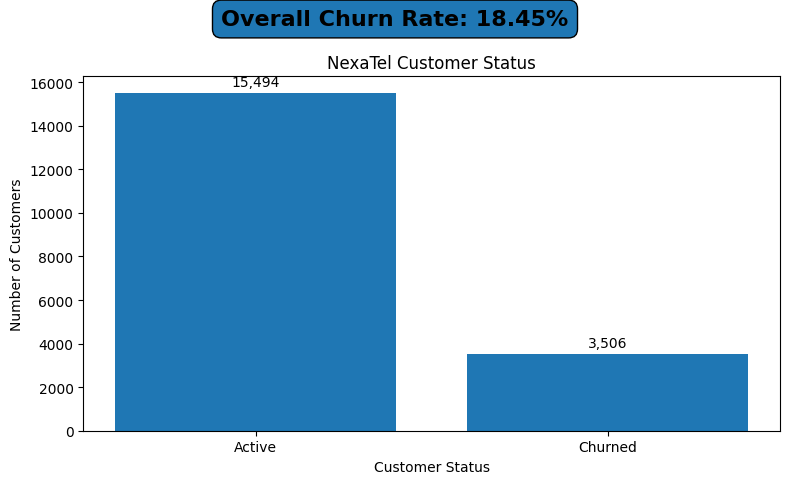

Saved: /mnt/data/nexatel_phase2_final/charts/01_overall_churn.png


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    status_counts.index,
    status_counts.values,
)

ax.set_title("NexaTel Customer Status")
ax.set_xlabel("Customer Status")
ax.set_ylabel("Number of Customers")

ax.bar_label(
    bars,
    labels=[
        f"{int(value):,}"
        for value in status_counts.values
    ],
    padding=3,
)

fig.text(
    0.5,
    0.94,
    f"Overall Churn Rate: {overall_churn_rate:.2f}%",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold",
    bbox={"boxstyle": "round,pad=0.4"},
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

chart_file = charts_path / "01_overall_churn.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", chart_file)

### 5.1.4 Observation

NexaTel has **3,506 churned customers out of
19,000 total customers**, resulting in an overall churn rate of
**18.45%**. Active customers still form the majority of the
base at **81.55%**, but the churn share is large enough
to warrant deeper analysis of customer, service, and plan-level drivers.

## 5.2 Churn by Billing Cycle

### 5.2.1 Map Each Customer to the Current Plan Billing Cycle

In [9]:
customer_plan = customers.merge(
    plans[
        [
            "plan_id",
            "billing_cycle",
            "monthly_charge",
        ]
    ],
    on="plan_id",
    how="left",
    validate="many_to_one",
)

print(
    "Customers with missing billing-cycle mapping:",
    int(customer_plan["billing_cycle"].isna().sum()),
)

display(
    customer_plan["billing_cycle"]
    .value_counts(dropna=False)
    .rename("customers")
    .to_frame()
)

Customers with missing billing-cycle mapping: 0


,customers
billing_cycle,
Monthly,13949
Annual,5051


### 5.2.2 Calculate Churn Rate by Billing Cycle

In [10]:
billing_cycle_summary = (
    customer_plan
    .groupby("billing_cycle")["customer_status"]
    .agg(
        total_customers="size",
        churned_customers=lambda x: (
            x == "Churned"
        ).sum(),
    )
)

billing_cycle_summary["churn_rate_pct"] = (
    billing_cycle_summary["churned_customers"]
    / billing_cycle_summary["total_customers"]
    * 100
)

billing_cycle_summary = (
    billing_cycle_summary
    .sort_values(
        "churn_rate_pct",
        ascending=False,
    )
)

display(billing_cycle_summary.round(2))

,total_customers,churned_customers,churn_rate_pct
billing_cycle,,,
Monthly,13949,3144,22.54
Annual,5051,362,7.17


### 5.2.3 Create Churn by Billing Cycle Chart

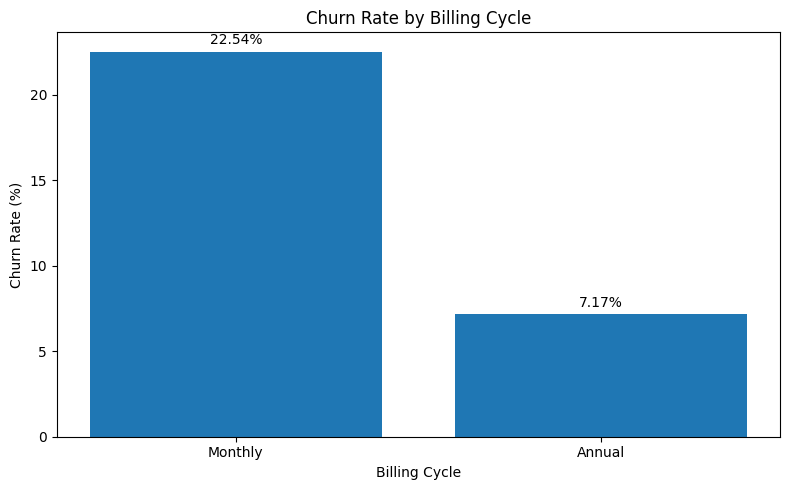

Saved: /mnt/data/nexatel_phase2_final/charts/02_churn_by_billing_cycle.png


In [11]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    billing_cycle_summary.index,
    billing_cycle_summary["churn_rate_pct"],
)

ax.set_title("Churn Rate by Billing Cycle")
ax.set_xlabel("Billing Cycle")
ax.set_ylabel("Churn Rate (%)")

ax.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in billing_cycle_summary["churn_rate_pct"]
    ],
    padding=3,
)

plt.tight_layout()

chart_file = charts_path / "02_churn_by_billing_cycle.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", chart_file)

### 5.2.4 Observation

Customers on **Monthly plans have a churn rate of 22.54%**,
compared with only **7.17% for Annual plans**. Monthly-plan
customers therefore churn at more than three times the annual-plan rate,
indicating that longer billing commitments are strongly associated with better
retention in this dataset.

## 5.3 Churn by Tenure Band

### 5.3.1 Create Non-Overlapping Tenure Bands

In [12]:
customers_tenure = customers.copy()

customers_tenure["tenure_band"] = pd.cut(
    customers_tenure["tenure_months"],
    bins=[-np.inf, 3, 12, 36, np.inf],
    labels=[
        "0-3m",
        "4-12m",
        "1-3y",
        "3y+",
    ],
)

display(
    customers_tenure["tenure_band"]
    .value_counts(sort=False)
    .rename("customers")
    .to_frame()
)

,customers
tenure_band,
0-3m,749
4-12m,1446
1-3y,2836
3y+,13969


The PRD labels the bands as `0-3m`, `3-12m`, `1-3y`, and `3y+`, which creates
overlap at the boundaries. For this notebook, the bands are implemented as
**0–3 months, 4–12 months, 13–36 months, and 37+ months** so that every customer
belongs to exactly one group.

### 5.3.2 Calculate Churn Rate by Tenure Band

In [13]:
tenure_summary = (
    customers_tenure
    .groupby(
        "tenure_band",
        observed=False,
    )["customer_status"]
    .agg(
        total_customers="size",
        churned_customers=lambda x: (
            x == "Churned"
        ).sum(),
    )
)

tenure_summary["churn_rate_pct"] = (
    tenure_summary["churned_customers"]
    / tenure_summary["total_customers"]
    * 100
)

display(tenure_summary.round(2))

,total_customers,churned_customers,churn_rate_pct
tenure_band,,,
0-3m,749,561,74.90
4-12m,1446,756,52.28
1-3y,2836,1026,36.18
3y+,13969,1163,8.33


### 5.3.3 Create Churn by Tenure Band Chart

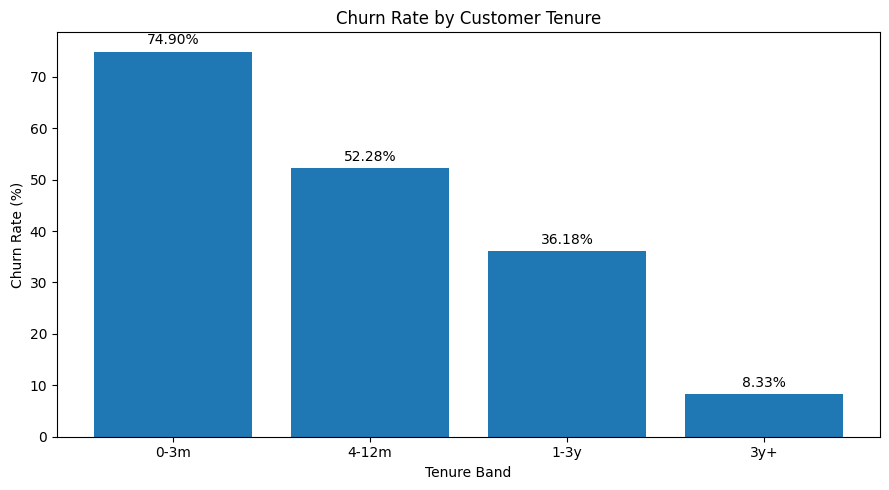

Saved: /mnt/data/nexatel_phase2_final/charts/03_churn_by_tenure.png


In [14]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    tenure_summary.index.astype(str),
    tenure_summary["churn_rate_pct"],
)

ax.set_title("Churn Rate by Customer Tenure")
ax.set_xlabel("Tenure Band")
ax.set_ylabel("Churn Rate (%)")

ax.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in tenure_summary["churn_rate_pct"]
    ],
    padding=3,
)

plt.tight_layout()

chart_file = charts_path / "03_churn_by_tenure.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", chart_file)

### 5.3.4 Observation

Churn is highest among customers in their first **0–3 months
(74.90%)** and falls steadily as
tenure increases: **52.28%** at
4–12 months, **36.18%** at 1–3
years, and only **8.33%** after
three years. This pattern indicates that the earliest stage of the customer
relationship is the most important retention window.

## 5.4 Churn by Number of Unresolved Complaints

### 5.4.1 Count Unresolved Complaints per Customer

In [15]:
unresolved_complaints = (
    complaints[
        complaints["status"]
        .astype("string")
        .str.strip()
        .str.lower()
        .eq("unresolved")
    ]
    .groupby("customer_id")
    .size()
    .rename("unresolved_complaints")
)

customer_complaints = (
    customers[
        ["customer_id", "customer_status"]
    ]
    .merge(
        unresolved_complaints,
        on="customer_id",
        how="left",
    )
)

customer_complaints[
    "unresolved_complaints"
] = (
    customer_complaints[
        "unresolved_complaints"
    ]
    .fillna(0)
    .astype(int)
)

display(
    customer_complaints[
        "unresolved_complaints"
    ]
    .value_counts()
    .sort_index()
    .rename("customers")
    .to_frame()
)

,customers
unresolved_complaints,
0,12942
1,4934
2,975
3,133
4,15
5,1


### 5.4.2 Group Sparse Complaint Counts and Calculate Churn

In [16]:
# Counts of 4 or 5 unresolved complaints contain very few customers.
# Group 3+ together to avoid unstable rates from tiny samples.
customer_complaints["unresolved_group"] = (
    customer_complaints["unresolved_complaints"]
    .clip(upper=3)
    .map({
        0: "0",
        1: "1",
        2: "2",
        3: "3+",
    })
)

complaint_churn_summary = (
    customer_complaints
    .groupby("unresolved_group")["customer_status"]
    .agg(
        total_customers="size",
        churned_customers=lambda x: (
            x == "Churned"
        ).sum(),
    )
)

complaint_churn_summary["churn_rate_pct"] = (
    complaint_churn_summary["churned_customers"]
    / complaint_churn_summary["total_customers"]
    * 100
)

complaint_churn_summary = (
    complaint_churn_summary
    .reindex(["0", "1", "2", "3+"])
)

display(complaint_churn_summary.round(2))

,total_customers,churned_customers,churn_rate_pct
unresolved_group,,,
0,12942,1956,15.11
1,4934,1153,23.37
2,975,325,33.33
3+,149,72,48.32


### 5.4.3 Create Unresolved Complaints vs Churn Chart

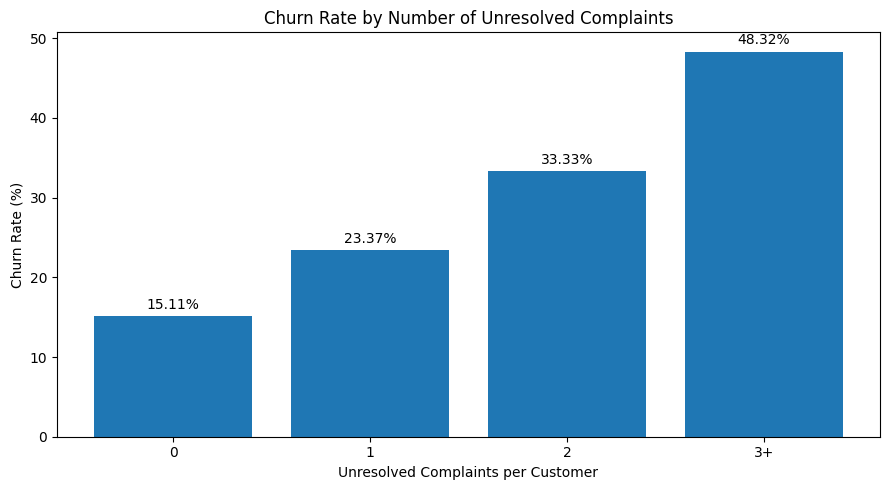

Saved: /mnt/data/nexatel_phase2_final/charts/04_churn_vs_unresolved_complaints.png


In [17]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    complaint_churn_summary.index,
    complaint_churn_summary["churn_rate_pct"],
)

ax.set_title("Churn Rate by Number of Unresolved Complaints")
ax.set_xlabel("Unresolved Complaints per Customer")
ax.set_ylabel("Churn Rate (%)")

ax.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in complaint_churn_summary["churn_rate_pct"]
    ],
    padding=3,
)

plt.tight_layout()

chart_file = charts_path / "04_churn_vs_unresolved_complaints.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", chart_file)

### 5.4.4 Observation

Churn rises consistently as unresolved complaints accumulate, increasing from
**15.11% for customers with no
unresolved complaints** to **23.37%**
with one and **33.33%** with two.
Customers with **3 or more unresolved complaints churn at
48.32%**, suggesting a strong
service-recovery opportunity for retention teams.

## 5.5 Churn by Customer Segment

### 5.5.1 Calculate Segment-Level Churn

In [18]:
segment_churn_summary = (
    customers
    .groupby("customer_segment")["customer_status"]
    .agg(
        total_customers="size",
        churned_customers=lambda x: (
            x == "Churned"
        ).sum(),
    )
)

segment_churn_summary["churn_rate_pct"] = (
    segment_churn_summary["churned_customers"]
    / segment_churn_summary["total_customers"]
    * 100
)

segment_churn_summary = (
    segment_churn_summary
    .sort_values(
        "churn_rate_pct",
        ascending=False,
    )
)

display(segment_churn_summary.round(2))

,total_customers,churned_customers,churn_rate_pct
customer_segment,,,
Mass,2932,782,26.67
Value,6196,1275,20.58
Premium,8482,1283,15.13
Enterprise,1390,166,11.94


### 5.5.2 Create Churn by Customer Segment Chart

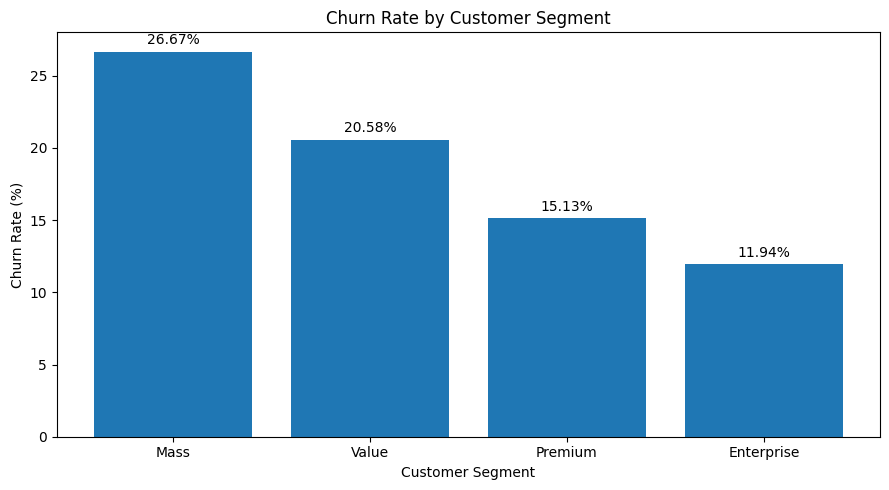

Saved: /mnt/data/nexatel_phase2_final/charts/05_churn_by_customer_segment.png


In [19]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    segment_churn_summary.index,
    segment_churn_summary["churn_rate_pct"],
)

ax.set_title("Churn Rate by Customer Segment")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Churn Rate (%)")

ax.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in segment_churn_summary["churn_rate_pct"]
    ],
    padding=3,
)

plt.tight_layout()

chart_file = charts_path / "05_churn_by_customer_segment.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", chart_file)

### 5.5.3 Observation

The **Mass segment has the highest churn rate at
26.67%**, followed by Value at
**20.58%**. Premium and Enterprise
customers churn less at **15.13%**
and **11.94%** respectively,
showing a clear retention gap between lower-value and higher-value segments.

## 5.6 Top 10 States by Churned Customers

### 5.6.1 Map Customer State IDs to State Names

In [20]:
customer_state = customers.merge(
    states[
        ["state_id", "state_name"]
    ],
    on="state_id",
    how="left",
    validate="many_to_one",
)

print(
    "Customers with missing state mapping:",
    int(
        customer_state["state_name"]
        .isna()
        .sum()
    ),
)

Customers with missing state mapping: 0


### 5.6.2 Identify Top 10 States by Churned-Customer Volume

In [21]:
top_10_states_churn = (
    customer_state[
        customer_state["customer_status"]
        .eq("Churned")
    ]
    .groupby("state_name")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

display(
    top_10_states_churn
    .rename("churned_customers")
    .to_frame()
)

,churned_customers
state_name,
Maharashtra,305
Uttar Pradesh,285
Tamil Nadu,280
Rajasthan,244
Karnataka,222
Gujarat,191
Madhya Pradesh,182
Kerala,162
Andhra Pradesh,160


### 5.6.3 Create Top 10 States Horizontal Bar Chart

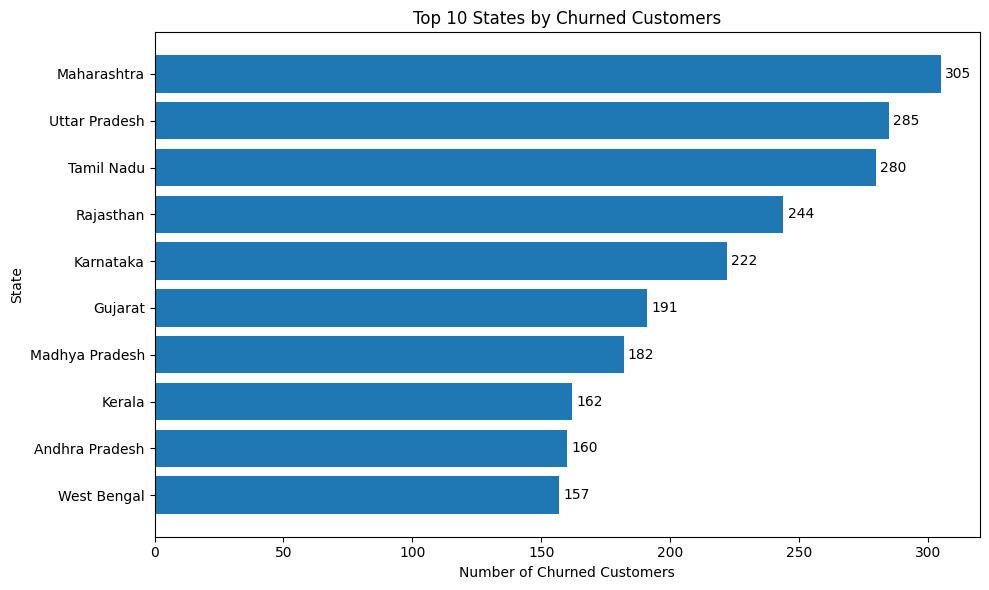

Saved: /mnt/data/nexatel_phase2_final/charts/06_top_10_states_by_churned_customers.png


In [22]:
plot_data = top_10_states_churn.sort_values()

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    plot_data.index,
    plot_data.values,
)

ax.set_title("Top 10 States by Churned Customers")
ax.set_xlabel("Number of Churned Customers")
ax.set_ylabel("State")

ax.bar_label(
    bars,
    labels=[
        f"{int(value):,}"
        for value in plot_data.values
    ],
    padding=3,
)

plt.tight_layout()

chart_file = charts_path / "06_top_10_states_by_churned_customers.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", chart_file)

### 5.6.4 Observation

**Maharashtra records the largest churned-customer volume with
305 customers**, followed by **Uttar Pradesh
with 285** and **Tamil Nadu with
280**. This chart ranks states by absolute churn volume,
so high counts may partly reflect a larger customer base; state-level churn
rates should be considered separately before prioritizing regional action.

## 5.7 Average Data Usage by City Tier

### 5.7.1 Join Cleaned Usage Records to Customer City Tier

In [23]:
usage_by_tier = usage_data[
    [
        "customer_id",
        "data_gb_used",
    ]
].merge(
    customers[
        [
            "customer_id",
            "city_tier",
        ]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one",
)

print(
    "Usage rows with missing city tier:",
    int(
        usage_by_tier["city_tier"]
        .isna()
        .sum()
    ),
)

print(
    "Usage rows excluded because Phase 1 marked "
    "the value as corrupted:",
    int(
        usage_by_tier["data_gb_used"]
        .isna()
        .sum()
    ),
)

Usage rows with missing city tier: 0
Usage rows excluded because Phase 1 marked the value as corrupted: 171


### 5.7.2 Calculate Average Data Usage

In [24]:
city_tier_usage = (
    usage_by_tier
    .groupby("city_tier")["data_gb_used"]
    .agg(
        valid_records="count",
        avg_data_gb="mean",
        median_data_gb="median",
    )
    .sort_values(
        "avg_data_gb",
        ascending=False,
    )
)

display(city_tier_usage.round(2))

,valid_records,avg_data_gb,median_data_gb
city_tier,,,
Metro,14538,36.06,26.43
Tier-2,27546,26.52,19.37
Tier-3,14745,18.36,13.43


### 5.7.3 Create Average Data Usage by City Tier Chart

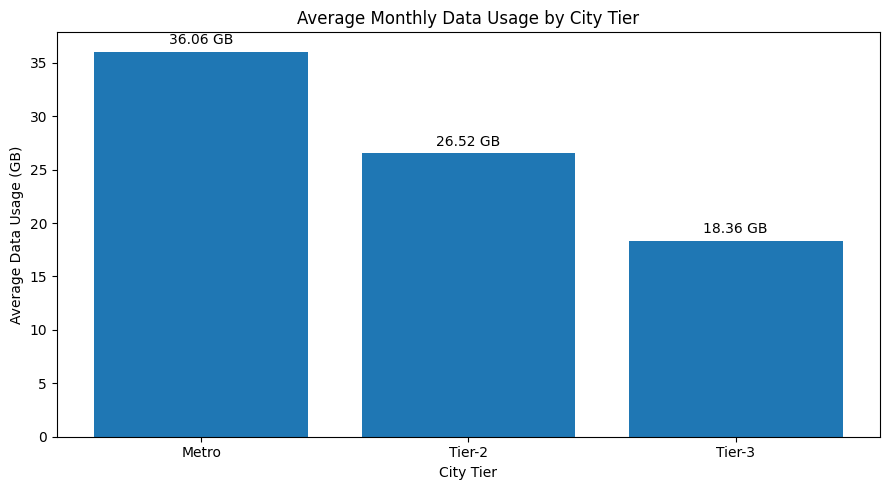

Saved: /mnt/data/nexatel_phase2_final/charts/07_avg_data_usage_by_city_tier.png


In [25]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    city_tier_usage.index,
    city_tier_usage["avg_data_gb"],
)

ax.set_title("Average Monthly Data Usage by City Tier")
ax.set_xlabel("City Tier")
ax.set_ylabel("Average Data Usage (GB)")

ax.bar_label(
    bars,
    labels=[
        f"{value:.2f} GB"
        for value in city_tier_usage["avg_data_gb"]
    ],
    padding=3,
)

plt.tight_layout()

chart_file = charts_path / "07_avg_data_usage_by_city_tier.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", chart_file)

### 5.7.4 Observation

Average monthly data usage is highest in **Metro cities at
36.06 GB**, followed by
**Tier-2 at 26.52 GB** and
**Tier-3 at 18.36 GB**.
The pattern shows a clear usage gradient by city tier, with Metro customers
consuming almost twice the average data volume of Tier-3 customers.

## 5.8 ARPU Distribution

### 5.8.1 Prepare Customer-Level Monthly Charge

In [26]:
# For this EDA visual, each customer's current plan monthly charge is used
# as a customer-level ARPU proxy, following the PRD instruction to plot
# monthly charge across the customer base.
customer_arpu = customers.merge(
    plans[
        [
            "plan_id",
            "monthly_charge",
        ]
    ],
    on="plan_id",
    how="left",
    validate="many_to_one",
)

arpu_values = (
    customer_arpu["monthly_charge"]
    .dropna()
)

print(
    "Customers included:",
    f"{len(arpu_values):,}",
)
print(
    "Mean monthly charge:",
    f"₹{arpu_values.mean():,.2f}",
)
print(
    "Median monthly charge:",
    f"₹{arpu_values.median():,.2f}",
)
print(
    "Maximum monthly charge:",
    f"₹{arpu_values.max():,.2f}",
)

Customers included: 19,000
Mean monthly charge: ₹818.30
Median monthly charge: ₹449.00
Maximum monthly charge: ₹8,333.00


### 5.8.2 Create ARPU Distribution Histogram

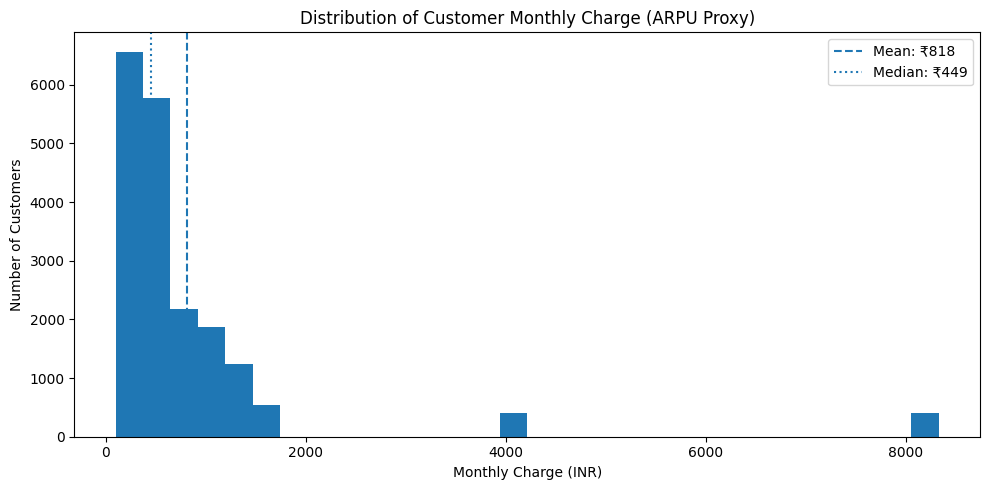

Saved: /mnt/data/nexatel_phase2_final/charts/08_arpu_distribution.png


In [27]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    arpu_values,
    bins=30,
)

ax.set_title("Distribution of Customer Monthly Charge (ARPU Proxy)")
ax.set_xlabel("Monthly Charge (INR)")
ax.set_ylabel("Number of Customers")

ax.axvline(
    arpu_values.mean(),
    linestyle="--",
    label=f"Mean: ₹{arpu_values.mean():,.0f}",
)

ax.axvline(
    arpu_values.median(),
    linestyle=":",
    label=f"Median: ₹{arpu_values.median():,.0f}",
)

ax.legend()

plt.tight_layout()

chart_file = charts_path / "08_arpu_distribution.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", chart_file)

### 5.8.3 Observation

The customer monthly-charge distribution is **right-skewed**, with a mean of
approximately **₹818.30** and a lower median of
**₹449.00**. Most customers are concentrated in lower-priced plans,
while a smaller number of high-value plans extend the upper tail and raise the
average.

## 5.9 Network Quality vs Churn

### 5.9.1 Aggregate Monthly Network Records to Customer Level

In [28]:
network_customer = (
    network_quality
    .groupby(
        "customer_id",
        as_index=False,
    )
    .agg(
        avg_dropped_call_rate_pct=(
            "dropped_call_rate_pct",
            "mean",
        ),
        avg_download_speed_mbps=(
            "avg_download_speed_mbps",
            "mean",
        ),
        avg_network_downtime_hours=(
            "network_downtime_hours",
            "mean",
        ),
    )
)

network_churn = network_customer.merge(
    customers[
        [
            "customer_id",
            "customer_status",
        ]
    ],
    on="customer_id",
    how="left",
    validate="one_to_one",
)

print(
    "Customer-level network records:",
    f"{len(network_churn):,}",
)

Customer-level network records: 19,000


### 5.9.2 Compare Dropped-Call Rate by Churn Status

In [29]:
network_churn_summary = (
    network_churn
    .groupby("customer_status")
    .agg(
        customers=("customer_id", "size"),
        avg_dropped_call_rate_pct=(
            "avg_dropped_call_rate_pct",
            "mean",
        ),
        avg_download_speed_mbps=(
            "avg_download_speed_mbps",
            "mean",
        ),
        avg_network_downtime_hours=(
            "avg_network_downtime_hours",
            "mean",
        ),
    )
)

display(network_churn_summary.round(3))

,customers,avg_dropped_call_rate_pct,avg_download_speed_mbps,avg_network_downtime_hours
customer_status,,,,
Active,15494,2.358,49.543,0.707
Churned,3506,2.594,46.915,0.763


### 5.9.3 Create Network Quality vs Churn Chart

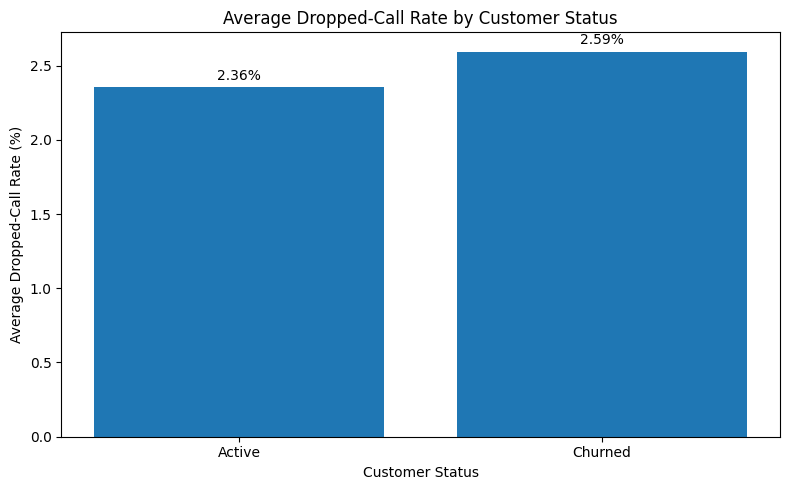

Saved: /mnt/data/nexatel_phase2_final/charts/09_network_quality_vs_churn.png


In [30]:
plot_network = (
    network_churn_summary
    .reindex(["Active", "Churned"])
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    plot_network.index,
    plot_network["avg_dropped_call_rate_pct"],
)

ax.set_title("Average Dropped-Call Rate by Customer Status")
ax.set_xlabel("Customer Status")
ax.set_ylabel("Average Dropped-Call Rate (%)")

ax.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in plot_network[
            "avg_dropped_call_rate_pct"
        ]
    ],
    padding=3,
)

plt.tight_layout()

chart_file = charts_path / "09_network_quality_vs_churn.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", chart_file)

### 5.9.4 Observation

Churned customers experienced an average dropped-call rate of
**2.59%**, compared with **2.36% for active
customers**—about **10.0% higher**. Churned customers also show lower
average download speed and slightly higher downtime in the supporting summary,
indicating that weaker network experience is associated with churn.

## 5.10 Retention Campaign Outcomes

### 5.10.1 Prepare Campaign Response and Retention Results

In [31]:
response_counts = (
    retention_campaigns["response"]
    .value_counts()
    .reindex(
        [
            "Accepted",
            "Declined",
            "No Response",
        ]
    )
)

campaign_outcomes = pd.crosstab(
    retention_campaigns["response"],
    retention_campaigns["retained_flag"],
)

campaign_outcomes = (
    campaign_outcomes
    .reindex(
        [
            "Accepted",
            "Declined",
            "No Response",
        ]
    )
    .fillna(0)
)

campaign_outcomes["total"] = (
    campaign_outcomes.sum(axis=1)
)

campaign_outcomes["retained_share_pct"] = (
    campaign_outcomes.get("Yes", 0)
    / campaign_outcomes["total"]
    * 100
)

display(campaign_outcomes.round(2))

overall_retained_share = (
    retention_campaigns["retained_flag"]
    .eq("Yes")
    .mean()
    * 100
)

print(
    "Overall retained share:",
    f"{overall_retained_share:.2f}%",
)

retained_flag,No,Yes,total,retained_share_pct
response,,,,
Accepted,393,2589,2982,86.82
Declined,391,1486,1877,79.17
No Response,354,1262,1616,78.09


Overall retained share: 82.42%


### 5.10.2 Create Retention Campaign Outcomes Chart

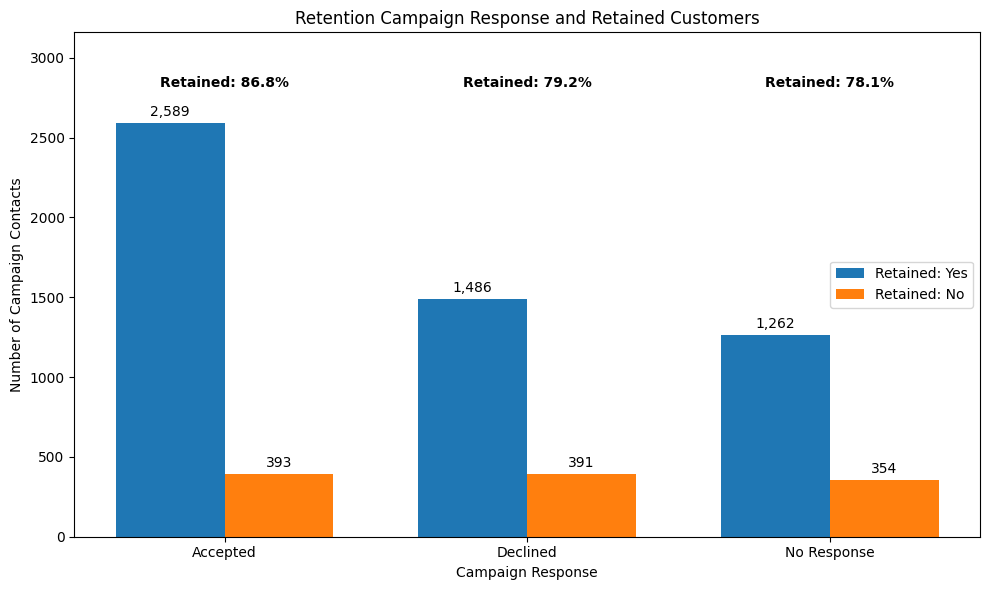

Saved: /mnt/data/nexatel_phase2_final/charts/10_retention_campaign_outcomes.png


In [32]:
plot_campaign = campaign_outcomes[
    [col for col in ["Yes", "No"] if col in campaign_outcomes.columns]
].copy()

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(plot_campaign.index))
width = 0.36

bars_collection = []

for i, column in enumerate(plot_campaign.columns):
    offset = (i - (len(plot_campaign.columns) - 1) / 2) * width

    bars = ax.bar(
        x + offset,
        plot_campaign[column].values,
        width,
        label=f"Retained: {column}",
    )

    bars_collection.append(bars)

    ax.bar_label(
        bars,
        labels=[
            f"{int(value):,}"
            for value in plot_campaign[column].values
        ],
        padding=3,
    )

ax.set_title("Retention Campaign Response and Retained Customers")
ax.set_xlabel("Campaign Response")
ax.set_ylabel("Number of Campaign Contacts")
ax.set_xticks(x)
ax.set_xticklabels(plot_campaign.index)
ax.legend()

max_height = plot_campaign.to_numpy().max()

for idx, response in enumerate(plot_campaign.index):
    rate = campaign_outcomes.loc[
        response,
        "retained_share_pct",
    ]

    ax.text(
        idx,
        max_height * 1.08,
        f"Retained: {rate:.1f}%",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

ax.set_ylim(
    0,
    max_height * 1.22,
)

plt.tight_layout()

chart_file = charts_path / "10_retention_campaign_outcomes.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", chart_file)

### 5.10.3 Observation

**Accepted offers are the largest response group
(2,982 contacts)** and have the highest retained
share at **86.82%**.
However, retained shares are also high among Declined
(**79.17%**) and No
Response (**78.09%**)
customers, so these results should be interpreted as campaign outcomes rather
than proof that accepting an offer caused retention.

## 6. EDA Summary

Phase 2 examined the main customer, plan, service, geographic, usage, network,
and retention patterns associated with NexaTel churn.

The 10 required visualizations have been completed and saved as PNG images.
The findings are summarized below.

### 6.1 Key Findings Summary

In [33]:
eda_summary = pd.DataFrame([
    [
        "Overall churn",
        f"{overall_churn_rate:.2f}% churn "
        f"({churned_customers:,} of {total_customers:,} customers).",
    ],
    [
        "Billing cycle",
        f"Monthly churn = {billing_cycle_summary.loc['Monthly', 'churn_rate_pct']:.2f}% "
        f"vs Annual = {billing_cycle_summary.loc['Annual', 'churn_rate_pct']:.2f}%.",
    ],
    [
        "Tenure",
        f"0-3m churn = {tenure_summary.loc['0-3m', 'churn_rate_pct']:.2f}%; "
        f"3y+ churn = {tenure_summary.loc['3y+', 'churn_rate_pct']:.2f}%.",
    ],
    [
        "Unresolved complaints",
        f"Churn rises from {complaint_churn_summary.loc['0', 'churn_rate_pct']:.2f}% "
        f"with 0 unresolved complaints to "
        f"{complaint_churn_summary.loc['3+', 'churn_rate_pct']:.2f}% with 3+.",
    ],
    [
        "Customer segment",
        f"Mass has the highest churn rate at "
        f"{segment_churn_summary.loc['Mass', 'churn_rate_pct']:.2f}%.",
    ],
    [
        "Top churn state",
        f"{top_10_states_churn.index[0]} has the highest churned-customer volume "
        f"({int(top_10_states_churn.iloc[0]):,}).",
    ],
    [
        "Data usage",
        f"Metro average usage = "
        f"{city_tier_usage.loc['Metro', 'avg_data_gb']:.2f} GB; "
        f"Tier-3 = {city_tier_usage.loc['Tier-3', 'avg_data_gb']:.2f} GB.",
    ],
    [
        "ARPU proxy",
        f"Mean monthly charge = ₹{arpu_values.mean():,.2f}; "
        f"median = ₹{arpu_values.median():,.2f}.",
    ],
    [
        "Network quality",
        f"Churned customers average "
        f"{network_churn_summary.loc['Churned', 'avg_dropped_call_rate_pct']:.2f}% "
        f"dropped calls vs "
        f"{network_churn_summary.loc['Active', 'avg_dropped_call_rate_pct']:.2f}% "
        f"for active customers.",
    ],
    [
        "Retention campaigns",
        f"Accepted offers have a "
        f"{campaign_outcomes.loc['Accepted', 'retained_share_pct']:.2f}% "
        f"retained share; overall retained share = {overall_retained_share:.2f}%.",
    ],
], columns=["Analysis", "Key Finding"])

display(eda_summary)

,Analysis,Key Finding
0,Overall churn,"18.45% churn (3,506 of 19,000 customers)."
1,Billing cycle,Monthly churn = 22.54% vs Annual = 7.17%.
2,Tenure,0-3m churn = 74.90%; 3y+ churn = 8.33%.
3,Unresolved complaints,Churn rises from 15.11% with 0 unresolved comp...
4,Customer segment,Mass has the highest churn rate at 26.67%.
5,Top churn state,Maharashtra has the highest churned-customer v...
6,Data usage,Metro average usage = 36.06 GB; Tier-3 = 18.36...
7,ARPU proxy,Mean monthly charge = ₹818.30; median = ₹449.00.
8,Network quality,Churned customers average 2.59% dropped calls ...
9,Retention campaigns,Accepted offers have a 86.82% retained share; ...


### 6.2 Key Business Insights

- **Early-life churn is the strongest pattern:** customers in their first
  0–3 months churn at **74.90%**,
  versus only **8.33%** after three
  years.

- **Monthly billing is a major retention risk:** Monthly customers churn at
  **22.54%**, substantially above Annual customers at
  **7.17%**.

- **Unresolved service problems matter:** churn increases from
  **15.11%** with no unresolved
  complaints to **48.32%** among
  customers with three or more unresolved complaints.

- **Mass customers are the most vulnerable segment:** the Mass segment records
  the highest segment churn rate at
  **26.67%**.

- **Network experience is weaker among churned customers:** their average
  dropped-call rate is about **10.0% higher** than that of active
  customers.

- **City-tier usage differs materially:** Metro customers use substantially
  more data on average than Tier-2 and Tier-3 customers, which may affect plan
  design and capacity priorities.

- **Retention-campaign acceptance is associated with the strongest retained
  share**, but this EDA does not establish causal campaign effectiveness.

### 6.3 Analytical Notes

1. **Tenure-band boundaries:** The PRD labels `0-3m` and `3-12m`, which overlap
   at month 3. This notebook uses 0–3, 4–12, 13–36, and 37+ months so every
   customer belongs to exactly one band.

2. **Top-state chart:** The geographic chart ranks states by the **number of
   churned customers**, as requested. It should not be interpreted as a
   state-level churn-rate ranking because states have different customer-base
   sizes.

3. **Usage cleaning:** Confirmed corrupted `data_gb_used` values identified in
   Phase 1 are excluded from average usage calculations, while plausible high
   usage is retained.

4. **ARPU visualization:** The PRD specifically asks for a histogram of monthly
   charge across the base. This notebook therefore uses the customer's current
   plan monthly charge as an **ARPU proxy** for this EDA chart. Formal ARPU in
   Phase 3 will follow the PRD KPI formula.

5. **Network aggregation:** Monthly network-quality records are first averaged
   to one row per customer before comparing churn groups. This prevents
   customers with repeated monthly records from being over-weighted.

6. **Retention campaigns:** Campaign response and retained status are
   observational outcomes. A higher retained share among Accepted customers is
   an association and does not by itself establish causal campaign lift.

## 7. Phase 2 Conclusion

Phase 2 — Exploratory Data Analysis successfully transformed the Phase 1
cleaned NexaTel datasets into churn-focused visual and business insights.

All **10 required analyses** were completed and saved as PNG images. The most
important patterns are the exceptionally high churn among new customers, the
large gap between Monthly and Annual billing-cycle churn, the steady increase
in churn as unresolved complaints accumulate, and weaker network quality among
churned customers.

The analysis also identifies meaningful differences across customer segments,
states, city tiers, monthly-charge levels, and retention-campaign outcomes.
These findings provide the analytical foundation for **Phase 3 — Churn KPI
Calculations**, where churn, retention, ARPU, CLV, revenue at risk, MRR, FCR,
resolution time, renewal rate, and tenure will be calculated formally.

**Phase 2 Status: COMPLETE ✅**

## 8. Phase 2 Requirement Checklist

In [34]:
phase2_checklist = pd.DataFrame([
    ["Overall churn KPI + Active vs Churned bar chart", "COMPLETE", "01_overall_churn.png"],
    ["Churn by billing cycle", "COMPLETE", "02_churn_by_billing_cycle.png"],
    ["Churn by tenure band", "COMPLETE", "03_churn_by_tenure.png"],
    ["Churn by unresolved complaints", "COMPLETE", "04_churn_vs_unresolved_complaints.png"],
    ["Churn by customer segment", "COMPLETE", "05_churn_by_customer_segment.png"],
    ["Top 10 states by churned customers", "COMPLETE", "06_top_10_states_by_churned_customers.png"],
    ["Average data usage by city tier", "COMPLETE", "07_avg_data_usage_by_city_tier.png"],
    ["ARPU distribution", "COMPLETE", "08_arpu_distribution.png"],
    ["Network quality vs churn", "COMPLETE", "09_network_quality_vs_churn.png"],
    ["Retention campaign outcomes", "COMPLETE", "10_retention_campaign_outcomes.png"],
    ["2-3 sentence observation for each analysis", "COMPLETE", "Notebook Markdown"],
    ["Save required charts as PNG", "COMPLETE", "outputs/charts"],
], columns=["Phase 2 Requirement", "Status", "Output"])

display(phase2_checklist)

png_files = sorted(charts_path.glob("*.png"))

print(f"PNG files created: {len(png_files)}")
for file in png_files:
    print(file.name)

,Phase 2 Requirement,Status,Output
0,Overall churn KPI + Active vs Churned bar chart,COMPLETE,01_overall_churn.png
1,Churn by billing cycle,COMPLETE,02_churn_by_billing_cycle.png
2,Churn by tenure band,COMPLETE,03_churn_by_tenure.png
3,Churn by unresolved complaints,COMPLETE,04_churn_vs_unresolved_complaints.png
4,Churn by customer segment,COMPLETE,05_churn_by_customer_segment.png
5,Top 10 states by churned customers,COMPLETE,06_top_10_states_by_churned_customers.png
6,Average data usage by city tier,COMPLETE,07_avg_data_usage_by_city_tier.png
7,ARPU distribution,COMPLETE,08_arpu_distribution.png
8,Network quality vs churn,COMPLETE,09_network_quality_vs_churn.png
9,Retention campaign outcomes,COMPLETE,10_retention_campaign_outcomes.png


PNG files created: 10
01_overall_churn.png
02_churn_by_billing_cycle.png
03_churn_by_tenure.png
04_churn_vs_unresolved_complaints.png
05_churn_by_customer_segment.png
06_top_10_states_by_churned_customers.png
07_avg_data_usage_by_city_tier.png
08_arpu_distribution.png
09_network_quality_vs_churn.png
10_retention_campaign_outcomes.png
